# 09 - Evaluation of the models (module 4)

Comparison of the four main models of the project on the **validation set**, with the shared functions of `src/evaluation.py`:

| Model | Notebook | What it is |
|---|---|---|
| Baseline | `03_baseline.ipynb` | TF-IDF (word unigrams) + logistic regression |
| Soft vote | `05_ensembles.ipynb` | Average of 3 linear models and a random forest |
| Transformer | `06_transformer_training.ipynb` | DistilBERT, weighted loss, average of 3 seeds |
| Transformer + baseline | `05_ensembles.ipynb`, section 8 | Average of the transformer and the baseline (the best combination of section 8, cheaper than with the vote) |

Sections: overall scores at the three label levels, per-label scores, calibration, robustness suite.

**Protocol.** Every score uses per-label thresholds cross-fitted on validation (tuned on one half, applied to the other) and a bootstrap 95% CI. The test set is **not** used here: it is scored once, in the final evaluation.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression

sys.path.append(os.path.join("..", "src"))
from evaluation import *

SEED = 42
DATA_DIR = os.path.join("..", "data", "processed")
RESULTS = os.path.join("..", "results")
OUT_DIR = os.path.join(RESULTS, "evaluation")
os.makedirs(OUT_DIR, exist_ok = True)

# one fixed colour per model in every figure
COLORS = {"Baseline": "#2a78d6", "Soft vote": "#eb6834", "Transformer": "#1baf7a", "Transformer + baseline": "#eda100"}

## 1. Data and model outputs

In [2]:
df_val = pd.read_parquet(os.path.join(DATA_DIR, "validation.parquet"))
assert len(df_val) == 5377, "re-run 01_eda_simple.ipynb"
y_val = to_multi_hot(df_val["labels_28"], LABELS_28)
y_val_levels = {level: to_multi_hot(df_val[level], classes) for level, classes in LEVELS.items()}

suite = pd.read_csv(os.path.join("..", "src", "robustness_suite.csv"))

def load(*parts):
    return np.load(os.path.join(RESULTS, *parts))

models = {
    "Baseline": {"val": load("baselines", "proba_val_best.npy"),
                 "suite": load("ensembles", "proba_suite_logreg_word.npy"),
                 "thresholds": load("baselines", "thresholds_best.npy")},
    "Soft vote": {"val": load("ensembles", "proba_val_voting_soft.npy"),
                  "suite": load("ensembles", "proba_suite_voting_soft.npy"),
                  "thresholds": load("ensembles", "thresholds_voting_soft.npy")},
    "Transformer": {"val": load("transformer", "proba_val_transformer.npy"),
                    "suite": load("transformer", "proba_suite_transformer.npy"),
                    "thresholds": load("transformer", "thresholds_transformer.npy")},
    "Transformer + baseline": {"val": load("ensembles", "proba_val_transformer_logreg.npy"),
                           "suite": load("ensembles", "proba_suite_transformer_logreg.npy"),
                           "thresholds": load("ensembles", "thresholds_transformer_logreg.npy")},
}
for name, m in models.items():
    assert m["val"].shape == (len(df_val), 28) and m["suite"].shape == (len(suite), 28)
    print(name, "- validation:", m["val"].shape, "suite:", m["suite"].shape)

Baseline - validation: (5377, 28) suite: (32, 28)
Soft vote - validation: (5377, 28) suite: (32, 28)
Transformer - validation: (5377, 28) suite: (32, 28)
Transformer + baseline - validation: (5377, 28) suite: (32, 28)


## 2. Overall scores at the three label levels

In [3]:
def crossfit_predict(y_true, proba, seed = SEED):
    rng = np.random.RandomState(seed)
    order = rng.permutation(len(y_true))
    half_a, half_b = order[: len(order) // 2], order[len(order) // 2 :]
    y_pred = np.zeros_like(y_true)
    for tune_idx, apply_idx in [(half_a, half_b), (half_b, half_a)]:
        thresholds_half = tune_thresholds(y_true[tune_idx], proba[tune_idx])
        y_pred[apply_idx] = apply_thresholds(proba[apply_idx], thresholds_half)
    return y_pred

y_pred = {name: crossfit_predict(y_val, m["val"]) for name, m in models.items()}

results_levels = pd.concat([evaluate_all_levels(name, y_pred[name], y_val_levels) for name in models], ignore_index = True)
results_levels.to_csv(os.path.join(OUT_DIR, "validation_results_levels.csv"), index = False)
format_results(results_levels)[["model", "level", "macro_f1", "micro_f1", "exact_match"]]

,model,level,macro_f1,micro_f1,exact_match
0,Baseline,28,"0.477 [0.456, 0.495]","0.521 [0.512, 0.530]",0.309
1,Baseline,ekman,"0.546 [0.527, 0.564]","0.620 [0.611, 0.630]",0.424
2,Baseline,sentiment,"0.615 [0.604, 0.625]","0.646 [0.636, 0.655]",0.447
3,Soft vote,28,"0.495 [0.474, 0.512]","0.550 [0.540, 0.559]",0.345
4,Soft vote,ekman,"0.569 [0.551, 0.587]","0.643 [0.634, 0.652]",0.466
5,Soft vote,sentiment,"0.641 [0.630, 0.653]","0.668 [0.659, 0.677]",0.490
6,Transformer,28,"0.524 [0.503, 0.541]","0.589 [0.579, 0.599]",0.401
7,Transformer,ekman,"0.616 [0.597, 0.635]","0.695 [0.686, 0.705]",0.547
8,Transformer,sentiment,"0.691 [0.680, 0.704]","0.721 [0.712, 0.730]",0.577
9,Transformer + baseline,28,"0.538 [0.518, 0.555]","0.597 [0.587, 0.607]",0.399


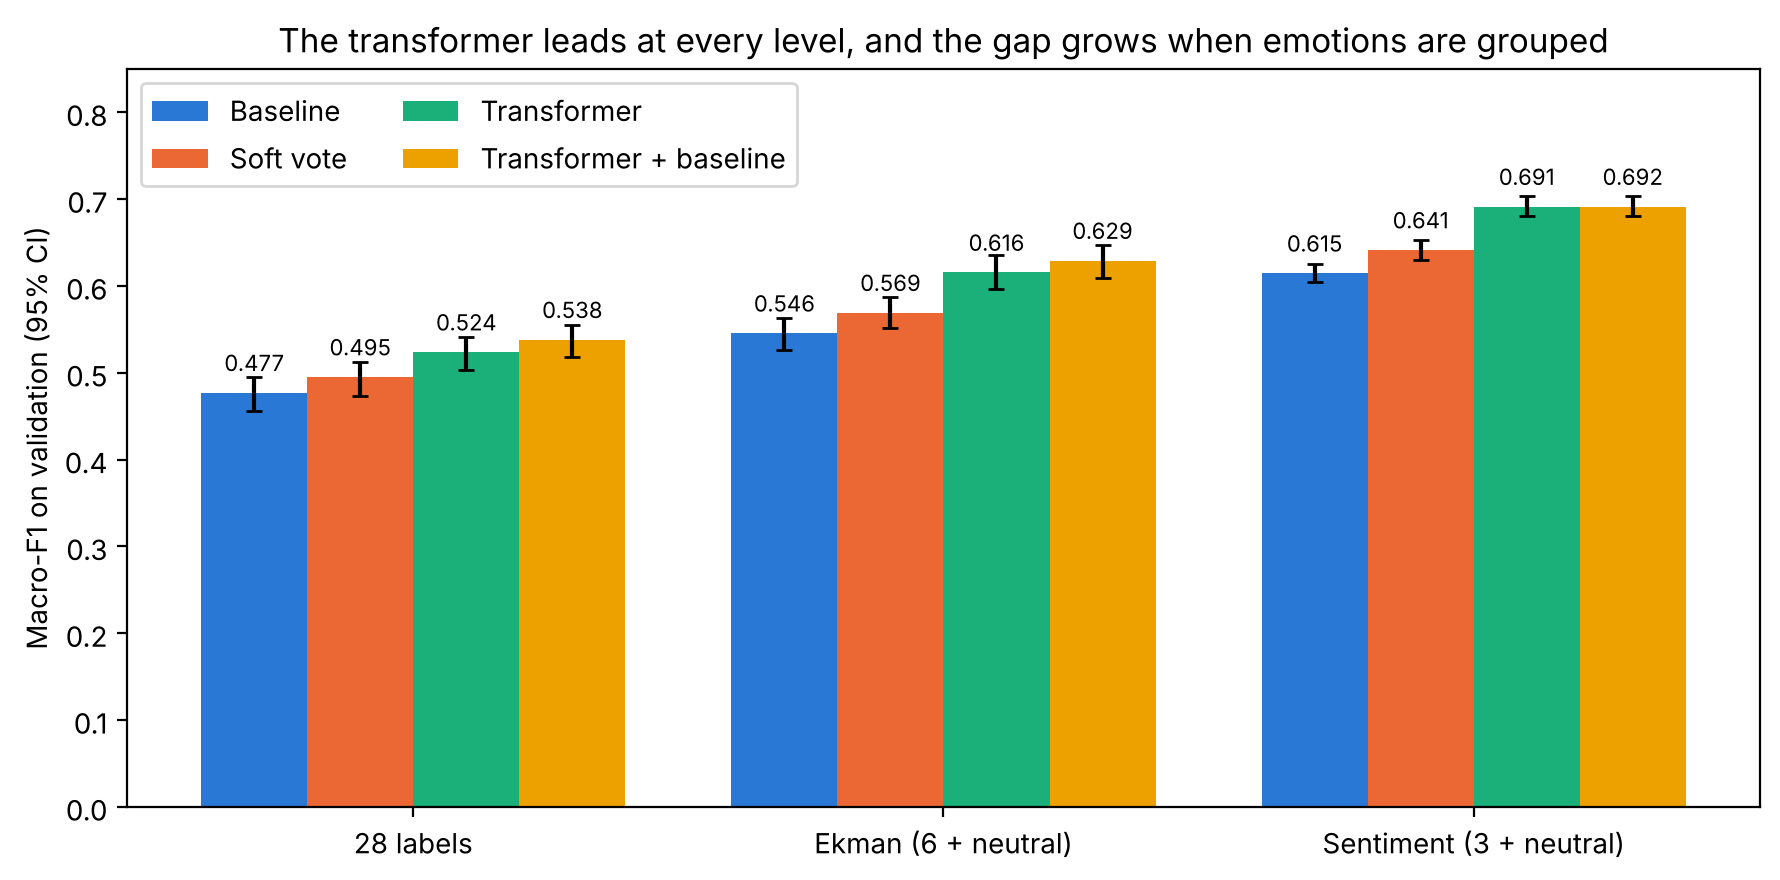

In [4]:
# main figure: macro-F1 with 95% CI, one group per label level
levels = ["28", "ekman", "sentiment"]
level_names = {"28": "28 labels", "ekman": "Ekman (6 + neutral)", "sentiment": "Sentiment (3 + neutral)"}
x = np.arange(len(levels))
width = 0.2

fig, ax = plt.subplots(figsize = (9, 4.5))
for k, name in enumerate(models):
    sub = results_levels[results_levels["model"] == name].set_index("level").loc[levels]
    err = np.vstack([sub["macro_f1"] - sub["macro_f1_low"], sub["macro_f1_high"] - sub["macro_f1"]])
    ax.bar(x + (k - 1.5) * width, sub["macro_f1"], width, yerr = err, capsize = 3, color = COLORS[name], label = name)
    for xi, v in zip(x + (k - 1.5) * width, sub["macro_f1"]):
        ax.text(xi, v + 0.025, str(round(v, 3)), ha = "center", fontsize = 8)
ax.set_xticks(x)
ax.set_xticklabels([level_names[l] for l in levels])
ax.set_ylabel("Macro-F1 on validation (95% CI)")
ax.set_ylim(0, 0.85)
ax.set_title("The transformer leads at every level, and the gap grows when emotions are grouped")
ax.legend(loc = "upper left", ncol = 2)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "macro_f1_by_level.png"))
plt.show()

Each model against the previous one, paired bootstrap on the same validation comments (28 labels):

In [5]:
order = list(models)
rows = []
for a, b in zip(order[:-1], order[1:]):
    res = paired_bootstrap(y_val, y_pred[a], y_pred[b])
    rows.append({"comparison": b + " vs " + a, "macro-F1 gain": res["diff_b_minus_a"],
                 "95% CI": "[" + str(round(res["ci_low"], 3)) + ", " + str(round(res["ci_high"], 3)) + "]",
                 "share of resamples with no gain": res["share_b_not_better"]})
res = paired_bootstrap(y_val, y_pred["Baseline"], y_pred["Transformer + baseline"])
rows.append({"comparison": "Transformer + baseline vs Baseline", "macro-F1 gain": res["diff_b_minus_a"],
             "95% CI": "[" + str(round(res["ci_low"], 3)) + ", " + str(round(res["ci_high"], 3)) + "]",
             "share of resamples with no gain": res["share_b_not_better"]})
paired_table = pd.DataFrame(rows).round(3)
paired_table.to_csv(os.path.join(OUT_DIR, "paired_bootstrap.csv"), index = False)
paired_table

,comparison,macro-F1 gain,95% CI,share of resamples with no gain
0,Soft vote vs Baseline,0.018,"[0.007, 0.028]",0.001
1,Transformer vs Soft vote,0.029,"[0.01, 0.048]",0.002
2,Transformer + baseline vs Transformer,0.014,"[0.002, 0.028]",0.011
3,Transformer + baseline vs Baseline,0.061,"[0.046, 0.078]",0.000


## 3. Per-label scores

In [6]:
per_label = pd.DataFrame({name: per_class_report(y_val, y_pred[name], LABELS_28)["f1"] for name in models})
per_label["support"] = per_class_report(y_val, y_pred["Baseline"], LABELS_28)["support"]
per_label["gain transformer vs baseline"] = per_label["Transformer"] - per_label["Baseline"]
per_label = per_label.sort_values("Transformer")
per_label.to_csv(os.path.join(OUT_DIR, "per_label_f1.csv"))
per_label.round(3)

,Baseline,Soft vote,Transformer,Transformer + baseline,support,gain transformer vs baseline
relief,0.214,0.214,0.222,0.229,18,0.008
realization,0.225,0.276,0.263,0.273,127,0.038
grief,0.560,0.500,0.316,0.455,13,-0.244
excitement,0.201,0.278,0.320,0.340,94,0.119
disappointment,0.203,0.254,0.338,0.385,162,0.135
nervousness,0.378,0.378,0.341,0.326,21,-0.037
annoyance,0.280,0.310,0.383,0.397,303,0.103
approval,0.290,0.293,0.394,0.405,394,0.104
confusion,0.323,0.357,0.416,0.417,149,0.093
disgust,0.406,0.417,0.418,0.448,96,0.012


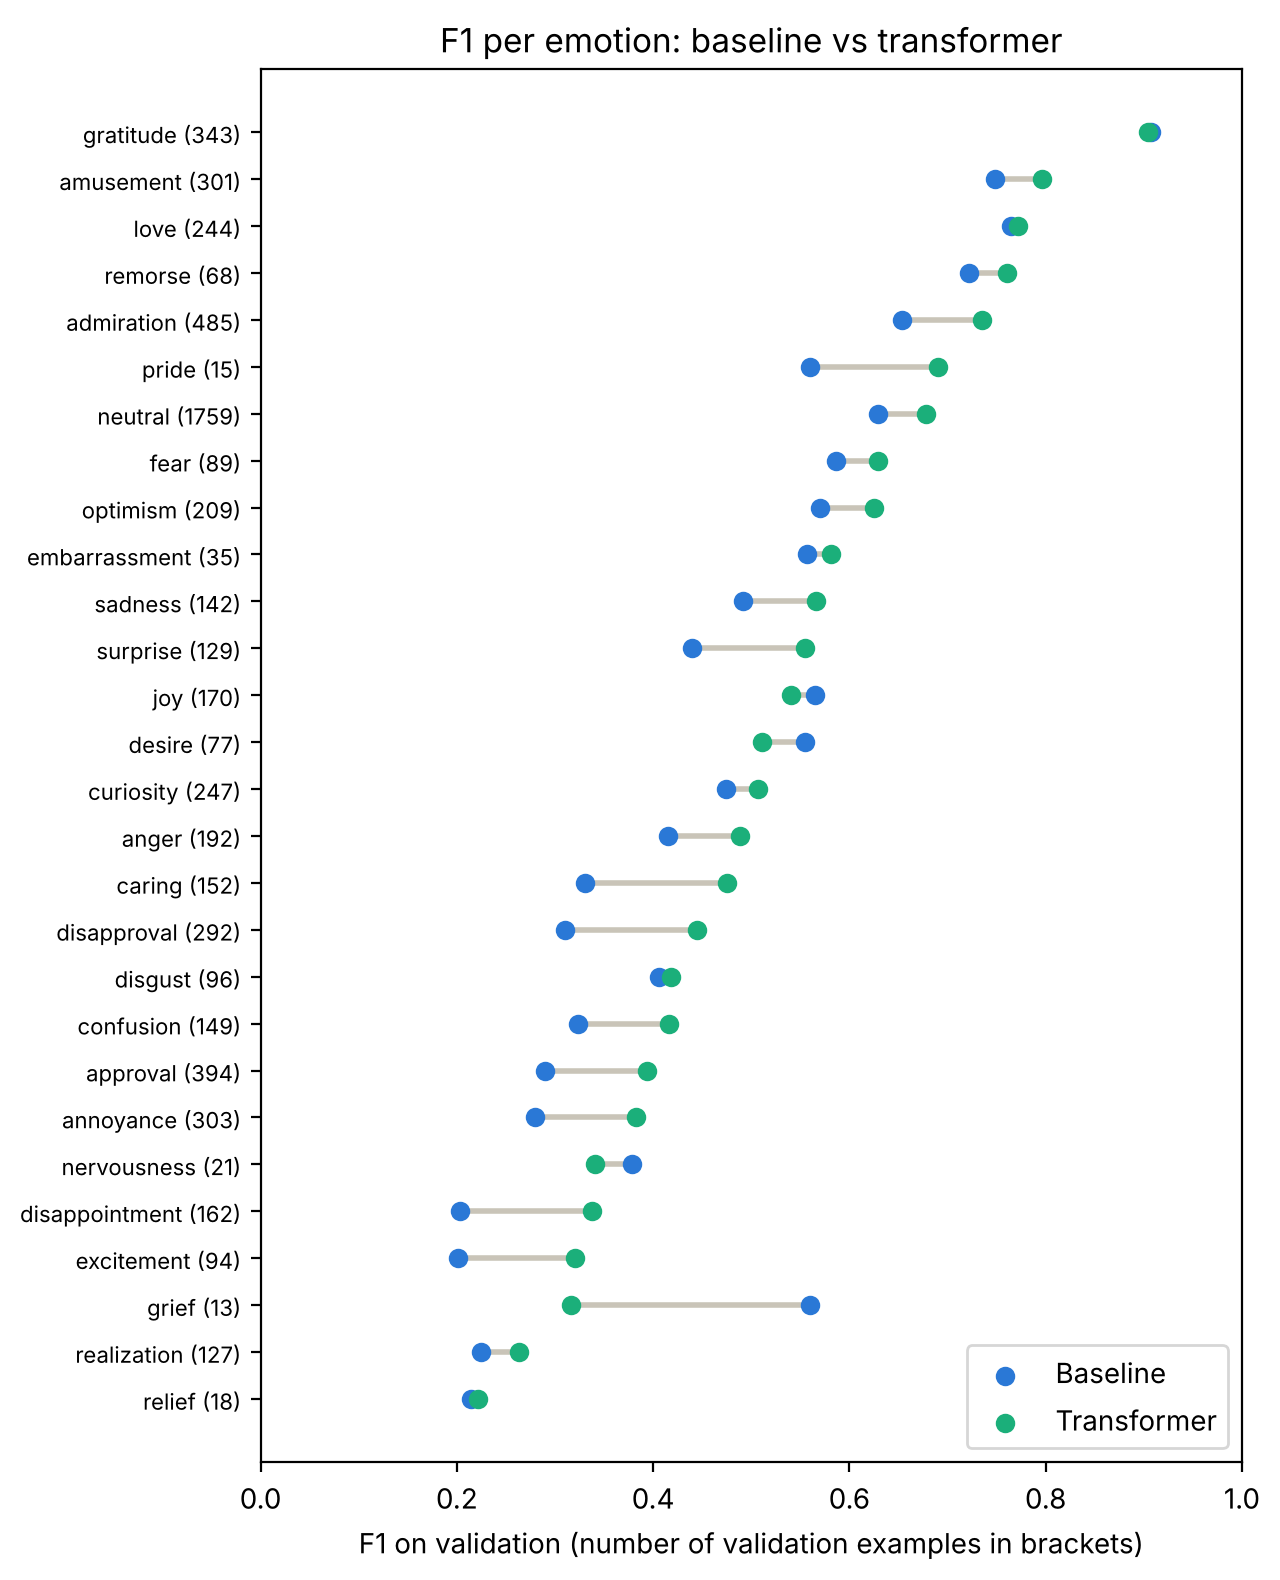

In [7]:
# dot plot: one line per label, baseline vs transformer
fig, ax = plt.subplots(figsize = (6.5, 8))
ypos = np.arange(len(per_label))
ax.hlines(ypos, per_label["Baseline"], per_label["Transformer"], color = "#c9c4b8", linewidth = 2)
ax.scatter(per_label["Baseline"], ypos, color = COLORS["Baseline"], label = "Baseline", zorder = 3)
ax.scatter(per_label["Transformer"], ypos, color = COLORS["Transformer"], label = "Transformer", zorder = 3)
ax.set_yticks(ypos)
ax.set_yticklabels([lab + " (" + str(int(s)) + ")" for lab, s in zip(per_label.index, per_label["support"])], fontsize = 8)
ax.set_xlim(0, 1)
ax.set_xlabel("F1 on validation (number of validation examples in brackets)")
ax.set_title("F1 per emotion: baseline vs transformer")
ax.legend(loc = "lower right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "per_label_f1_baseline_vs_transformer.png"))
plt.show()

## 4. Calibration

A model is **calibrated** when its probabilities can be read as frequencies: among the comments given 0.7 for "joy", about 70% should really be joy. This matters if the scores are shown to a user (sub-question 3 of the specification).

- **Brier score:** mean squared error between probability and 0/1 label (lower is better).
- **ECE (expected calibration error):** average gap between predicted probability and observed frequency, by bins of probability.

Both are averaged over the 28 labels.

In [8]:
cal_rows = []
for name, m in models.items():
    cal_rows.append({"model": name,
                     "Brier (mean over labels)": brier_per_label(y_val, m["val"], LABELS_28).mean(),
                     "ECE (mean over labels)": expected_calibration_error(y_val, m["val"]).mean()})
calibration_table = pd.DataFrame(cal_rows)
calibration_table.round(4)

,model,Brier (mean over labels),ECE (mean over labels)
0,Baseline,0.0264,0.0079
1,Soft vote,0.0259,0.0206
2,Transformer,0.0300,0.0393
3,Transformer + baseline,0.0240,0.0204


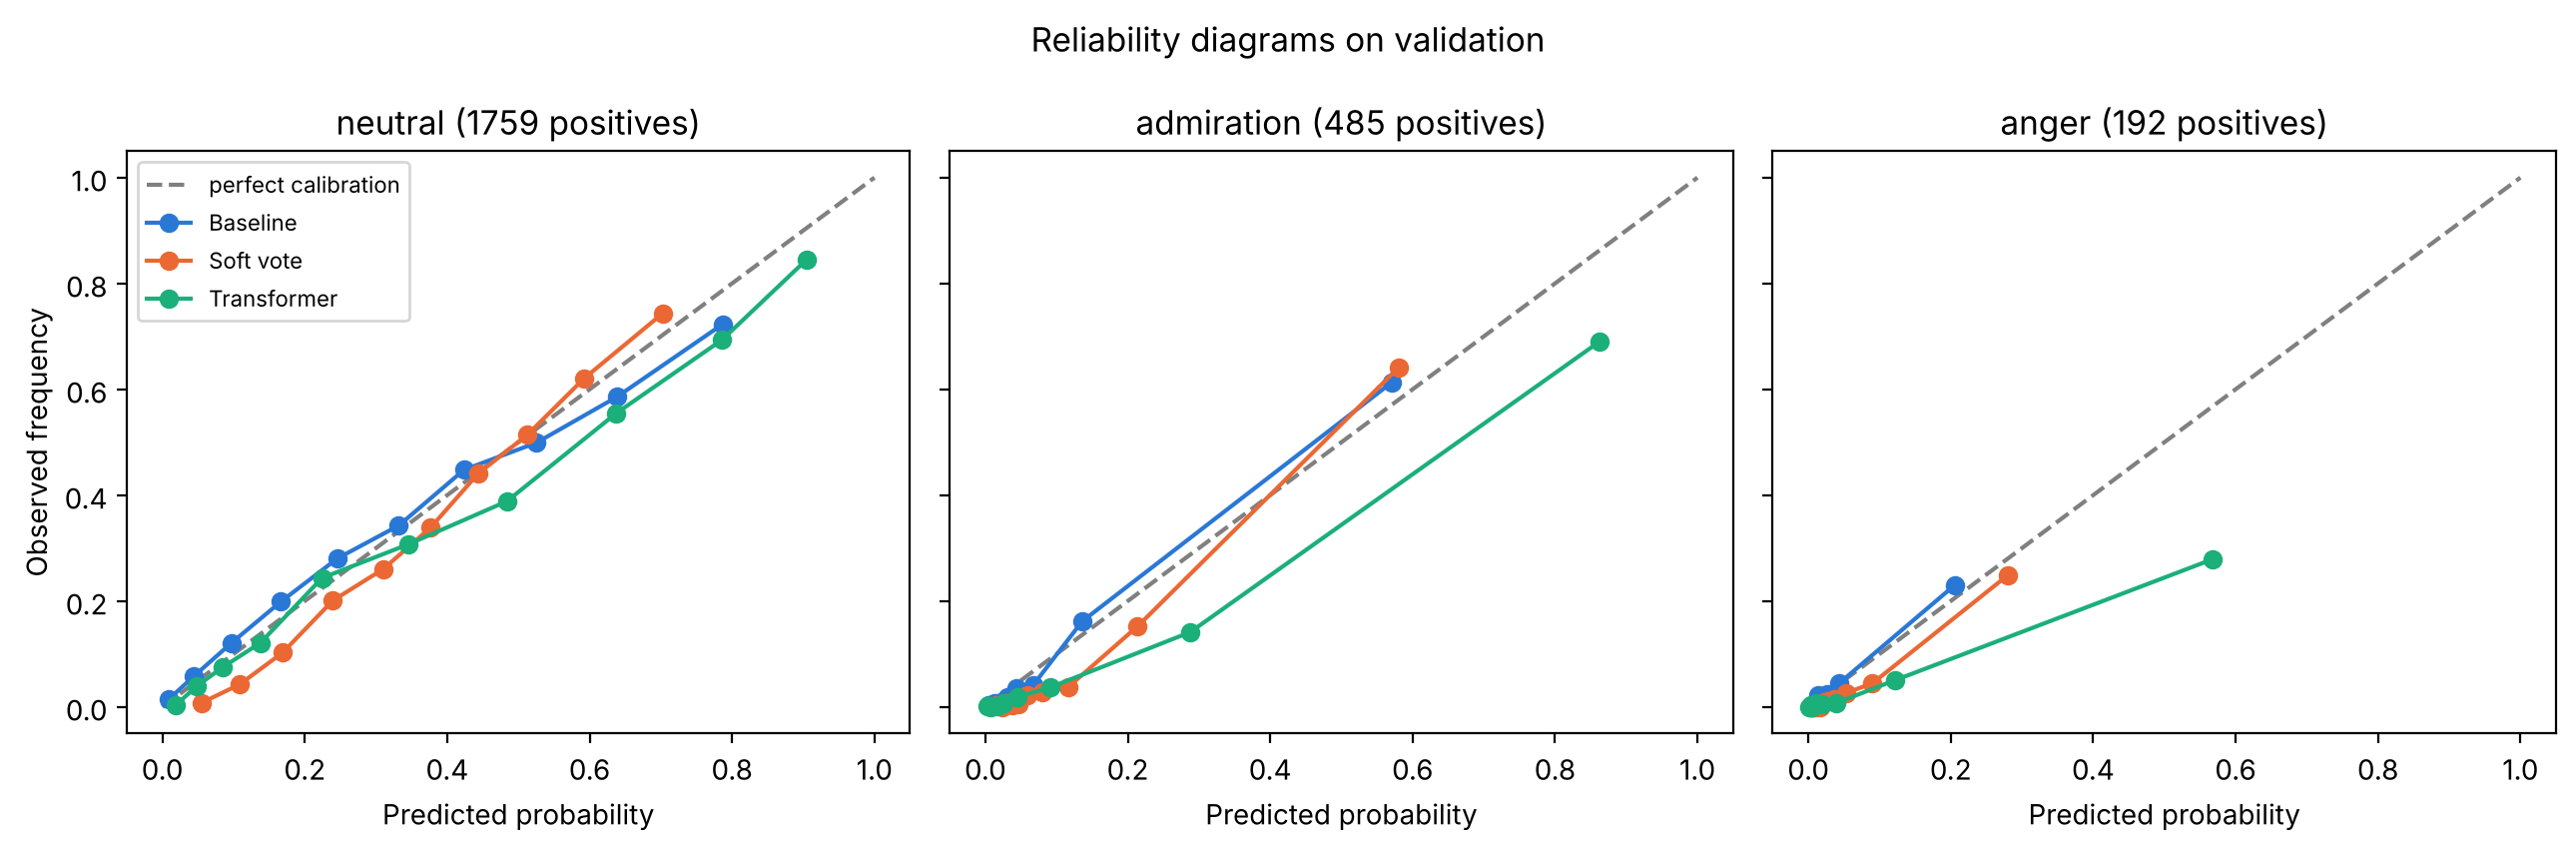

In [9]:
fig, axes = plt.subplots(1, 3, figsize = (13, 4.3), sharey = True)
for ax, label in zip(axes, ["neutral", "admiration", "anger"]):
    j = LABELS_28.index(label)
    ax.plot([0, 1], [0, 1], "--", color = "grey", label = "perfect calibration")
    for name in ["Baseline", "Soft vote", "Transformer"]:
        from sklearn.calibration import calibration_curve
        frac_pos, mean_pred = calibration_curve(y_val[:, j], models[name]["val"][:, j], n_bins = 10, strategy = "quantile")
        ax.plot(mean_pred, frac_pos, marker = "o", color = COLORS[name], label = name)
    ax.set_title(label + " (" + str(int(y_val[:, j].sum())) + " positives)")
    ax.set_xlabel("Predicted probability")
axes[0].set_ylabel("Observed frequency")
axes[0].legend(fontsize = 8)
plt.suptitle("Reliability diagrams on validation")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "reliability_diagrams.png"))
plt.show()

**Recalibration.** One isotonic regression per label maps the scores to observed frequencies. Fitting and measuring it on the same comments would be optimistic, so we cross-fit it like the thresholds: fit on one half of validation, measure on the other half, then swap.

In [10]:
def crossfit_isotonic(y_true, proba, seed = SEED):
    rng = np.random.RandomState(seed)
    order = rng.permutation(len(y_true))
    half_a, half_b = order[: len(order) // 2], order[len(order) // 2 :]
    calibrated = np.zeros_like(proba, dtype = float)
    for fit_idx, apply_idx in [(half_a, half_b), (half_b, half_a)]:
        calibrators = fit_calibrators(y_true[fit_idx], proba[fit_idx], method = "isotonic")
        calibrated[apply_idx] = apply_calibrators(calibrators, proba[apply_idx])
    return calibrated

for row in cal_rows:
    calibrated = crossfit_isotonic(y_val, models[row["model"]]["val"])
    row["Brier after isotonic"] = brier_per_label(y_val, calibrated, LABELS_28).mean()
    row["ECE after isotonic"] = expected_calibration_error(y_val, calibrated).mean()
calibration_table = pd.DataFrame(cal_rows)
calibration_table.to_csv(os.path.join(OUT_DIR, "calibration.csv"), index = False)
calibration_table.round(4)

,model,Brier (mean over labels),ECE (mean over labels),Brier after isotonic,ECE after isotonic
0,Baseline,0.0264,0.0079,0.0261,0.0041
1,Soft vote,0.0259,0.0206,0.0253,0.0041
2,Transformer,0.0300,0.0393,0.0228,0.0044
3,Transformer + baseline,0.0240,0.0204,0.0231,0.0045


## 5. Robustness suite

32 hand-written messages in six categories (negation, sarcasm, very short texts, clear cases, mixed emotions, neutral facts), in `src/robustness_suite.csv`.
Each model predicts labels with its final thresholds (tuned on the whole validation set). A message counts as a **hit** when at least one of its expected labels is predicted. With 2 to 7 messages per category the intervals (Wilson 95%) are wide: the suite shows *where* the models fail, not precise rates.

**Warning:** the expected labels are a first draft that the team has not reviewed yet (some are debatable, e.g. "I wouldn't say I'm angry." → neutral). Re-run this section after the review.

In [11]:
robust_summary = []
robust_detail = suite.copy()
for name, m in models.items():
    y_suite = apply_thresholds(m["suite"], m["thresholds"])
    predicted = [[LABELS_28[j] for j in np.where(row == 1)[0]] for row in y_suite]
    detail, summary = evaluate_robustness(suite, predicted)
    summary["model"] = name
    robust_summary.append(summary)
    robust_detail[name] = detail["predicted"]
    robust_detail[name + " hit"] = detail["hit"]

robust_summary = pd.concat(robust_summary, ignore_index = True)
robust_summary.to_csv(os.path.join(OUT_DIR, "robustness_summary.csv"), index = False)
robust_detail.to_csv(os.path.join(OUT_DIR, "robustness_detail.csv"), index = False)

table = robust_summary.pivot(index = "category", columns = "model", values = "hit_rate")[list(models)]
table["n"] = robust_summary.groupby("category")["n"].first()
table.round(2)

model,Baseline,Soft vote,Transformer,Transformer + baseline,n
category,,,,,
ALL,0.66,0.66,0.69,0.72,32
clear,1.00,1.00,1.00,1.00,7
mixed,1.00,1.00,1.00,1.00,3
negation,0.29,0.29,0.57,0.57,7
neutral_fact,1.00,1.00,1.00,1.00,2
sarcasm,0.00,0.00,0.00,0.00,6
short,1.00,1.00,0.86,1.00,7


In [12]:
# messages that every model misses, and messages where the transformer is right and the baseline wrong
hit_cols = [name + " hit" for name in models]
print("Missed by every model:")
print(robust_detail[~robust_detail[hit_cols].any(axis = 1)][["text", "category", "expected", "Transformer"]].to_string(index = False))
print()
print("Transformer right, baseline wrong:")
print(robust_detail[robust_detail["Transformer hit"] & ~robust_detail["Baseline hit"]][["text", "category", "expected", "Baseline", "Transformer"]].to_string(index = False))

Missed by every model:
                                         text category                 expected       Transformer
                             I don't hate it. negation                 approval anger;disapproval
                    I wouldn't say I'm angry. negation                  neutral             anger
     Nothing about this makes me sad anymore. negation                   relief           sadness
Oh great, another Monday. Just what I needed.  sarcasm annoyance;disappointment        admiration
                     Wow, thanks for nothing.  sarcasm annoyance;disappointment         gratitude
 Yeah, because that worked so well last time.  sarcasm    disapproval;annoyance          approval
 Sure, I just love waiting two hours on hold.  sarcasm          annoyance;anger              love
              Brilliant idea, really. Genius.  sarcasm    disapproval;annoyance        admiration
           Oh fantastic, my phone died again.  sarcasm annoyance;disappointment             gri

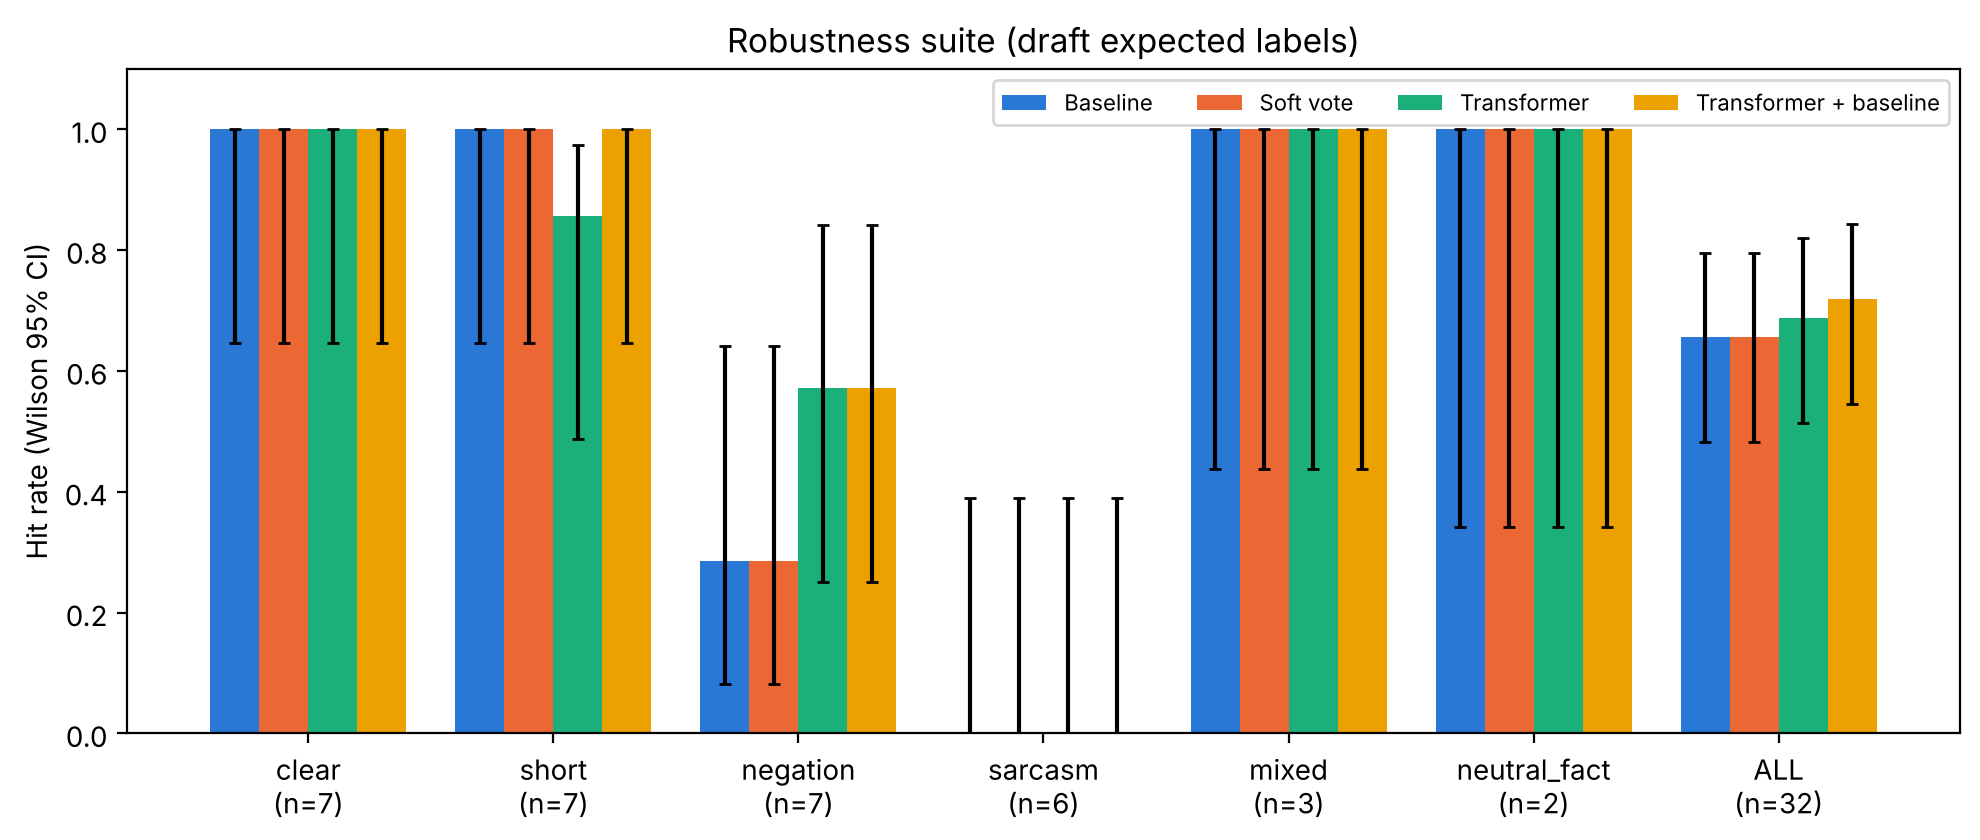

In [13]:
cats = ["clear", "short", "negation", "sarcasm", "mixed", "neutral_fact", "ALL"]
x = np.arange(len(cats))
width = 0.2
fig, ax = plt.subplots(figsize = (10, 4.3))
for k, name in enumerate(models):
    sub = robust_summary[robust_summary["model"] == name].set_index("category").loc[cats]
    err = np.vstack([sub["hit_rate"] - sub["ci_low"], sub["ci_high"] - sub["hit_rate"]])
    ax.bar(x + (k - 1.5) * width, sub["hit_rate"], width, yerr = err, capsize = 2, color = COLORS[name], label = name)
ax.set_xticks(x)
ax.set_xticklabels([c + "\n(n=" + str(int(robust_summary.set_index("category").loc[c, "n"].iloc[0])) + ")" for c in cats])
ax.set_ylabel("Hit rate (Wilson 95% CI)")
ax.set_ylim(0, 1.1)
ax.set_title("Robustness suite (draft expected labels)")
ax.legend(ncol = 4, fontsize = 8, loc = "upper right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "robustness_suite.png"))
plt.show()

## 6. Summary (validation set)

**Overall** (macro-F1, cross-fitted per-label thresholds, 95% CI):

| Model | 28 labels | Ekman | Sentiment |
|---|---|---|---|
| Baseline | 0.477 [0.456, 0.495] | 0.546 | 0.615 |
| Soft vote | 0.495 [0.474, 0.512] | 0.569 | 0.641 |
| Transformer | 0.524 [0.503, 0.541] | 0.616 | 0.691 |
| **Transformer + baseline** | **0.538 [0.518, 0.555]** | **0.629** | **0.692** |

- **Every step is a significant gain** in the paired bootstrap: soft vote vs baseline +0.018 [0.007, 0.028], transformer vs soft vote +0.029 [0.010, 0.048], transformer + baseline vs transformer +0.014 [0.002, 0.028]. In total, +0.061 [0.046, 0.078] over the baseline.
- **The gap grows when emotions are grouped** (transformer vs baseline: +0.05 on 28 labels, +0.08 on sentiment): the transformer reads the polarity of a sentence much better, even when it still confuses close emotions.

**Per emotion.** The transformer helps most on emotions expressed without a fixed word (caring, disapproval, disappointment, approval, annoyance: +0.10 to +0.14). Emotions with a strong cue word stay the same (gratitude 0.90 for all models). Some rare emotions do not improve: grief falls from 0.56 to 0.32 (13 validation examples, so a few comments) and relief stays near 0.22. Adding the baseline to the transformer recovers part of grief (0.46): the word "RIP" is a cue the linear model never misses.

**Calibration.**
- The linear baseline is well calibrated (ECE 0.008): its probabilities can be read as frequencies.
- The transformer is the **worst calibrated** (ECE 0.039) and **overconfident**: on the reliability diagrams, when it says 0.85 for admiration, admiration is right only about 70% of the time. This is expected from the weighted loss, which pushes the probabilities of rare labels up to improve recall.
- Isotonic recalibration (cross-fitted) fixes it: ECE falls to about 0.004 for every model, and the transformer gets the best Brier score (0.023). Recalibration changes the probabilities, not their order, so the F1 scores above stay valid with re-tuned thresholds.
- **Consequence:** if probabilities are shown to a user, the transformer must be recalibrated first; for the labels alone it does not matter.

**Robustness suite** (32 messages, draft expected labels, hit rates):

| Category (n) | Baseline | Soft vote | Transformer | Transformer + baseline |
|---|---|---|---|---|
| Clear (7), mixed (3), neutral facts (2) | 1.00 | 1.00 | 1.00 | 1.00 |
| Very short (7) | 1.00 | 1.00 | 0.86 | 1.00 |
| Negation (7) | 0.29 | 0.29 | 0.57 | 0.57 |
| **Sarcasm (6)** | **0.00** | **0.00** | **0.00** | **0.00** |
| All (32) | 0.66 | 0.66 | 0.69 | 0.72 |

- **Negation:** the transformer reads "not happy" and "not bad" correctly (4 of 7), the bag-of-words models only 2 of 7: they see "happy" and "bad".
- **Sarcasm is the main failure of every model:** "Wow, thanks for nothing." is read as gratitude, "Sure, I just love waiting two hours on hold." as love. The models follow the literal words. Sarcasm is also rare and inconsistently labelled in Reddit training data.
- With 6 or 7 messages per category the Wilson intervals are very wide: these are illustrations of failure modes, not measured rates. The expected labels must still be reviewed by the team.

**Final model:** the average of the transformer and the baseline (best macro-F1, cheap to add). It will be scored once on the test set in the final evaluation, with the thresholds tuned on the whole validation set (`results/ensembles/thresholds_transformer_logreg.npy`).